# 01. ALPHA data and research design

The main branch aims to predict the first attempt at a new programming task and to develop AlphaProg-AGMT on RoboMission trajectories. An independent school branch predicts the final cCTt score from the pre-test score and the characteristics available in January. The unit of observation in the school branch is a student row; independence is limited by nesting within classes and schools.

The sources cannot be linked at the learner level. The final cCTt score is not a measure of independent programming. The absence of programming events does not permit inventing programming labels or presenting the school model as an implementation of AlphaProg-AGMT.

[School data, CC BY 4.0](https://zenodo.org/records/7489244); [RoboMission documentation](https://github.com/adaptive-learning/robomission/blob/master/docs/data.md).

In [1]:
from pathlib import Path
import json
import hashlib
import urllib.request
import urllib.error
import platform


def verify_frozen_training_source(root: Path) -> None:
    """Allow exact-source reproduction without pretending a viewed test is new."""
    boundary = root / "Protocol/test_evaluation_boundary.json"
    if not boundary.exists():
        return
    frozen_sources = json.loads(
        (root / "Protocol/frozen_training_sources.json").read_text()
    )
    for filename, expected in frozen_sources["notebooks"].items():
        notebook = json.loads((root / "Notebooks" / filename).read_text())
        source = "\n\n".join(
            "".join(cell["source"])
            for cell in notebook["cells"]
            if cell["cell_type"] == "code"
        )
        observed = hashlib.sha256(source.encode()).hexdigest()
        assert (
            observed == expected
        ), "Training source changed after the test was opened."


from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
assert ROOT.name == "ALPHA"
SEED = 20260923
rng = np.random.default_rng(SEED)
font_names = {font.name for font in font_manager.fontManager.ttflist}
assert "Times New Roman" in font_names
FONT = "Times New Roman"
FONT_SIZE, TITLE_SIZE, FIGURE_DPI = 18, 20, 350
mpl.rcParams.update(
    {
        "font.family": FONT,
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "mathtext.fontset": "stix",
    }
)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


def table(frame: pd.DataFrame, caption: str, name: str) -> None:
    """Display a complete DataFrame using Jupyter's default table styling."""
    frame.to_csv(ROOT / "Tables" / f"{name}.csv", index=False)
    with pd.option_context(
        "display.max_rows",
        None,
        "display.max_columns",
        None,
        "display.max_colwidth",
        None,
        "display.width",
        None,
    ):
        display(Markdown(caption))
        display(frame.reset_index(drop=True).round(3))


def save_figure(fig: mpl.figure.Figure, name: str) -> None:
    """Save at 350 dpi after checking the font contract on visible text."""
    from matplotlib.text import Text

    fig.canvas.draw()
    for text in fig.findobj(match=Text):
        if text.get_visible() and text.get_text():
            assert 18 <= text.get_fontsize() <= 20
            assert text.get_fontfamily() == ["Times New Roman"]
    fig.savefig(ROOT / "Figures" / f"{name}.png", dpi=FIGURE_DPI)
    fig.savefig(ROOT / "Figures" / f"{name}.pdf", dpi=FIGURE_DPI)


verify_frozen_training_source(ROOT)

## Acquisition and recording of source files

Zenodo files are verified against the published MD5 checksums; SHA-256 is computed additionally. Raw data are stored unchanged. Network errors are recorded in the log rather than replaced with empty or synthetic observations. The availability of RoboMission documentation does not imply the availability of the dataset itself.

In [2]:
raw = ROOT / "Data" / "Raw" / "zenodo_7489244"
record_url = "https://zenodo.org/api/records/7489244"
if not (raw / "record.json").exists():
    (raw / "record.json").write_bytes(
        urllib.request.urlopen(record_url, timeout=30).read()
    )
record = json.loads((raw / "record.json").read_text())
manifest = []
for item in record["files"]:
    path = raw / item["key"]
    if not path.exists():
        path.write_bytes(
            urllib.request.urlopen(item["links"]["self"], timeout=40).read()
        )
    blob = path.read_bytes()
    assert "md5:" + hashlib.md5(blob).hexdigest() == item["checksum"]
    manifest.append(
        {
            "file": str(path.relative_to(ROOT)),
            "source": item["links"]["self"],
            "bytes": len(blob),
            "sha256": hashlib.sha256(blob).hexdigest(),
            "source_md5": item["checksum"],
        }
    )
(ROOT / "Protocol" / "source_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)
datasets = {p.stem: pd.read_csv(p) for p in sorted(raw.glob("*.csv"))}
assert len(datasets) == 3
school = datasets["student_test_janjune_2021"].copy()
required = [
    "City",
    "School",
    "Class",
    "Pre-test cCTt score",
    "Post-test cCTt score",
    "Students' grade",
    "Students' gender",
]
assert set(required).issubset(school.columns)
assert school["Unnamed: 0"].is_unique
school = school.rename(columns={"Unnamed: 0": "source_row"})
# This index preserves source identity; it is not a cross-source learner identifier.
robo_paths = [
    p for p in (ROOT / "Data" / "Raw" / "robomission").rglob("*.csv")
]
robo_present = {"events.csv", "attempts.csv", "problems.csv"}.issubset(
    {p.name for p in robo_paths}
)

## Composition of sources

Which observed outcomes are actually present in each file? The sizes below are computed from the files and may differ from the sizes of the analytical samples in the publication.

In [3]:
rows = []
roles = {
    "student_test_janjune_2021": "Longitudinal cCTt: January — June 2021",
    "student_surveytest_nov_2021": "Cross-section of cCTt and perception: November 2021",
    "student_survey_may_2022": "Perception: May 2022",
}
for name, frame in datasets.items():
    rows.append(
        {
            "Source": roles[name],
            "Rows": len(frame),
            "Columns": frame.shape[1],
            "Schools": frame["School"].nunique(),
            "Classes (labels)": frame["Class"].nunique(),
        }
    )
table(
    pd.DataFrame(rows),
    "Table 1. Actual composition of the school data",
    "01_source_composition",
)

Table 1. Actual composition of the school data

,Source,Rows,Columns,Schools,Classes (labels)
0,Perception: May 2022,1644,30,5,85
1,Cross-section of cCTt and perception: November 2021,2456,45,7,130
2,Longitudinal cCTt: January — June 2021,1470,46,7,83


**Interpretation.** The files contain 1,644, 2,456 and 1,470 rows, respectively; these values describe the export, not the cleaned samples of the article.

## Completeness of longitudinal observations

Missing targets are not reconstructed by imputation. Rows with identical observed scores are not removed as duplicate students: coincidences are possible in an anonymised dataset. Row numbering is not used as a predictor.

In [4]:
pre, post = "Pre-test cCTt score", "Post-test cCTt score"
for col in [pre, post]:
    observed = school[col].dropna()
    assert (
        observed.between(0, 24).all()
        and np.equal(observed, observed.round()).all()
    )
eligible = school[school[pre].notna() & school[post].notna()].copy()
quality = pd.DataFrame(
    [
        ["All rows", len(school)],
        ["Pre-test score missing", int(school[pre].isna().sum())],
        ["Final score missing", int(school[post].isna().sum())],
        ["Both scores available", len(eligible)],
        [
            "Repeated source row indices",
            int(school.source_row.duplicated().sum()),
        ],
        [
            "Fully identical rows, index excluded",
            int(school.drop(columns="source_row").duplicated().sum()),
        ],
    ],
    columns=["Characteristic", "Count"],
)
table(
    quality,
    "Table 2. Completeness and repetition of longitudinal observations",
    "01_longitudinal_quality",
)

Table 2. Completeness and repetition of longitudinal observations

,Characteristic,Count
0,All rows,1470
1,Pre-test score missing,7
2,Final score missing,7
3,Both scores available,1463
4,Repeated source row indices,0
5,"Fully identical rows, index excluded",51


**Interpretation.** The longitudinal file contains 1,463 complete score pairs. The 51 rows that coincide when the index is excluded are retained: without a learner identifier, a repeated record of the same person cannot be proven.

## Temporal availability of features

The source README assigns teacher perception to January, before the pre-test, and teacher adoption to June, after the final test. The main school protocol permits the pre-test, the school grade and 16 teacher perception/motivation measures. Student gender is used only for subgroup analysis. Ratings of the professional development programme are excluded conservatively, because their specific timing is not specified.

In [5]:
teacher_cols = [
    c
    for c in school
    if c.startswith("The teachers' perception")
    or c.startswith("Autonomous motivation")
]
features = [pre, "Students' grade"] + teacher_cols
assert len(teacher_cols) == 16
for c in teacher_cols:
    assert school[c].dropna().between(-3, 3).all()
assert not any(
    "Number of periods" in c or "Post-test" in c or "change" in c
    for c in features
)
feature_contract = {
    "features": features,
    "target": post,
    "pretest": pre,
    "teacher_features": teacher_cols,
    "group_columns": ["City", "School"],
    "sensitive_analysis_only": ["Students' gender"],
    "exclude": [c for c in school if c not in features + [post]],
}
(ROOT / "Protocol" / "school_features.json").write_text(
    json.dumps(feature_contract, ensure_ascii=False, indent=2)
)
table(
    pd.DataFrame(
        [
            ["Pre-test cCTt and grade", 2, "Before prediction", "Input"],
            [
                "Teacher perception and motivation",
                len(teacher_cols),
                "January 2021",
                "Input",
            ],
            [
                "Number of lessons delivered",
                sum(c.startswith("Number of periods") for c in school),
                "June, after post-test",
                "Excluded",
            ],
            [
                "Professional development rating",
                sum(c.startswith("The teachers' CS PD") for c in school),
                "Not separately established",
                "Excluded",
            ],
            ["Final cCTt", 1, "June 2021", "Target"],
            [
                "Score change",
                1,
                "Uses the final target",
                "Excluded from inputs",
            ],
        ],
        columns=["Group", "Features", "Availability", "Role"],
    ),
    "Table 3. Prediction contract",
    "01_feature_availability",
)

Table 3. Prediction contract

,Group,Features,Availability,Role
0,Pre-test cCTt and grade,2,Before prediction,Input
1,Teacher perception and motivation,16,January 2021,Input
2,Number of lessons delivered,15,"June, after post-test",Excluded
3,Professional development rating,6,Not separately established,Excluded
4,Final cCTt,1,June 2021,Target
5,Score change,1,Uses the final target,Excluded from inputs


**Interpretation.** The input is restricted to 18 features; 15 measures of lessons delivered and 6 professional development ratings are excluded. This prevents the inclusion of future measurements.

## Fixed school-level split

Schools are assigned by a deterministic hash of the identifier and seed, without selection based on scores. Two schools are reserved for the locked final evaluation, one for validation and the remainder for training. Inner folds hold out an entire school. Preprocessing is fitted within each fold. Such a small set of schools limits the precision of estimates of cross-school transfer; a single validation school does not replace external replication. Test scores are not analysed further.

In [6]:
eligible["school_group"] = (
    eligible[["City", "School"]].astype(str).agg("|".join, axis=1)
)
eligible["class_group"] = (
    eligible[["City", "School", "Class"]].astype(str).agg("|".join, axis=1)
)
groups = sorted(
    eligible.school_group.unique(),
    key=lambda g: hashlib.sha256(f"{SEED}:{g}".encode()).hexdigest(),
)
assert len(groups) >= 7
assignment = {
    g: ("locked_test" if i < 2 else "validation" if i == 2 else "train")
    for i, g in enumerate(groups)
}
eligible["split"] = eligible.school_group.map(assignment)
split_manifest = eligible[
    ["source_row", "school_group", "class_group", "split"]
]
manifest_path = ROOT / "Protocol" / "school_split.csv"
if manifest_path.exists():
    pd.testing.assert_frame_equal(
        pd.read_csv(manifest_path),
        split_manifest.reset_index(drop=True),
        check_dtype=False,
    )
else:
    split_manifest.to_csv(manifest_path, index=False)
for part in ["train", "validation", "locked_test"]:
    eligible[eligible.split == part].to_pickle(
        ROOT / "Data" / "Processed" / f"school_{part}.pkl"
    )
train = eligible[eligible.split == "train"]
assert train.school_group.nunique() >= 3
summary = (
    eligible.groupby("split")
    .agg(
        Students=("source_row", "size"),
        Schools=("school_group", "nunique"),
        Classes=("class_group", "nunique"),
    )
    .reset_index()
)
table(summary, "Table 4. Split without school overlap", "01_school_split")
protocol = {
    "seed": SEED,
    "primary_metric": "MAE",
    "secondary_metrics": ["RMSE", "R2"],
    "seeds": [17, 42, 2026],
    "inner_cv": "LeaveOneGroupOut by school on train",
    "validation": "One held-out school; selection evidence is exploratory",
    "locked_test": "Two held-out schools; do not read during development",
    "split_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "robo_data_available": robo_present,
    "no_linkage_between_sources": True,
}
(ROOT / "Protocol" / "school_protocol.json").write_text(
    json.dumps(protocol, indent=2)
);

Table 4. Split without school overlap

,split,Students,Schools,Classes
0,locked_test,397,2,21
1,train,909,4,52
2,validation,157,1,9


**Interpretation.** The school split contains 909 training, 157 validation and 397 locked test observations. Generalisation across schools is limited by their small number.

## The real RoboMission archive

The archive dated 10 December 2019 was obtained from the public folder referenced by the [official research repository](https://github.com/adaptive-learning/adaptive-learning-research/tree/master/data/robomission-2019-02-09). The name of the repository section refers to February, but both archives are available in the linked folder. Only the December version is used; the overlapping February archive is not an independent external validation.

The attempts table is an aggregate of events. Final fields of an attempt are prohibited as features of that same attempt. Edit events carry no correctness label. Age and membership of Generation Alpha are not confirmed here.

In [7]:
import zipfile

robo_raw = ROOT / "Data" / "Raw" / "robomission"
archive = robo_raw / "robomission-2019-12-10.zip"
assert zipfile.is_zipfile(archive)
robo_dir = robo_raw / "robomission-2019-12-10"
events = pd.read_csv(robo_dir / "events.csv")
attempts = pd.read_csv(robo_dir / "attempts.csv")
problems = pd.read_csv(robo_dir / "problems.csv")
assert {
    "id",
    "event_order",
    "timestamp",
    "event_type",
    "student",
    "problem",
    "attempt",
    "program",
    "correct",
}.issubset(events)
assert events.id.is_unique and attempts.id.is_unique and problems.id.is_unique
assert (
    events.attempt.isin(attempts.id).all()
    and events.problem.isin(problems.id).all()
)
assert (
    not events[["student", "problem", "attempt", "timestamp"]]
    .isna()
    .any()
    .any()
)
events["timestamp"] = pd.to_datetime(
    events.timestamp, format="mixed", utc=True
)
attempts["start"] = pd.to_datetime(attempts.start, format="mixed", utc=True)
assert events.event_order.is_monotonic_increasing
events["program"] = events.program.fillna("")
assert set(events.event_type.unique()) <= {"edit", "execution"}
assert events.loc[events.event_type == "edit", "correct"].isna().all()
assert set(events.correct.dropna().unique()) <= {0, 1}
robo_present = True
manifest.append(
    {
        "file": str(archive.relative_to(ROOT)),
        "source": "https://drive.google.com/file/d/1iKgMZFcKy5J1Ry9K7sUVeLAHK1fq-xJV/view",
        "official_reference": "https://github.com/adaptive-learning/adaptive-learning-research/tree/master/data/robomission-2019-02-09",
        "bytes": archive.stat().st_size,
        "sha256": hashlib.sha256(archive.read_bytes()).hexdigest(),
    }
)
for p in sorted(robo_dir.glob("*.csv")):
    manifest.append(
        {
            "file": str(p.relative_to(ROOT)),
            "bytes": p.stat().st_size,
            "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
            "archive": archive.name,
        }
    )
(ROOT / "Protocol" / "source_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2)
)
table(
    pd.DataFrame(
        [
            ["Events", len(events)],
            ["Attempts", len(attempts)],
            ["Learners", events.student.nunique()],
            ["Tasks", len(problems)],
            ["Edits", int((events.event_type == "edit").sum())],
            ["Runs", int((events.event_type == "execution").sum())],
            [
                "Runs without outcome",
                int(
                    events.loc[events.event_type == "execution", "correct"]
                    .isna()
                    .sum()
                ),
            ],
        ],
        columns=["Unit of observation", "Count"],
    ),
    "Table 5. Actual composition of RoboMission",
    "01_robomission_composition",
)

Table 5. Actual composition of RoboMission

,Unit of observation,Count
0,Events,2615264
1,Attempts,164707
2,Learners,11675
3,Tasks,85
4,Edits,2050253
5,Runs,565011
6,Runs without outcome,0


**Interpretation.** A total of 2,615,264 events from 11,675 learners were obtained. Among the 565,011 runs there are no missing correctness labels; edit labels remain empty.

## Event consistency and the prediction unit

For each learner, the first visit to each new task is considered. The target is the correctness of the first recorded run within this visit. Visits without a run are counted in the description of the selection but do not receive an imputed negative label. The prediction time is the start of the visit. The history includes only information available before this moment; the first program for the new task is not an input to the main experiment.

In [8]:
execution = events[
    (events.event_type == "execution") & events.correct.notna()
].copy()
first_execution = (
    execution.sort_values(["timestamp", "event_order"])
    .drop_duplicates("attempt")
    .set_index("attempt")
)
first_visit = (
    attempts.sort_values(["start", "id"])
    .drop_duplicates(["student", "problem"])
    .copy()
)
first_visit["y"] = first_visit.id.map(first_execution.correct)
first_visit["first_execution_time"] = first_visit.id.map(
    first_execution.timestamp
)
cohort = first_visit[first_visit.y.notna()].copy()
cohort["y"] = cohort.y.astype(int)
assert (cohort.first_execution_time >= cohort.start).all()
# Join cardinality and ownership checks use all events, not a sample.
owner = attempts.set_index("id")
assert np.array_equal(
    events.student.to_numpy(), events.attempt.map(owner.student).to_numpy()
)
assert np.array_equal(
    events.problem.to_numpy(), events.attempt.map(owner.problem).to_numpy()
)
execution_count = (
    events.event_type.eq("execution").groupby(events.attempt).sum()
)
edit_count = events.event_type.eq("edit").groupby(events.attempt).sum()
solved_event = events.correct.eq(1).groupby(events.attempt).any()
consistency = pd.DataFrame(
    [
        ["First visit to a new task", len(first_visit)],
        ["First visit with an observed run", len(cohort)],
        [
            "First visit without a run label",
            int(first_visit.y.isna().sum()),
        ],
        [
            "Run count mismatch",
            int(
                (
                    owner.n_executions
                    != execution_count.reindex(owner.index, fill_value=0)
                ).sum()
            ),
        ],
        [
            "Edit count mismatch",
            int(
                (
                    owner.n_edits
                    != edit_count.reindex(owner.index, fill_value=0)
                ).sum()
            ),
        ],
        [
            "Final success mismatch",
            int(
                (
                    owner.solved
                    != solved_event.reindex(owner.index, fill_value=False)
                ).sum()
            ),
        ],
        [
            "Timestamp reversals",
            int((events.timestamp.diff().dt.total_seconds() < 0).sum()),
        ],
    ],
    columns=["Characteristic", "Count"],
)
assert consistency.iloc[3:, 1].eq(0).all()
table(
    consistency.iloc[:3],
    "Table 6. Observability of the first run",
    "01_robo_quality",
)

Table 6. Observability of the first run

,Characteristic,Count
0,First visit to a new task,157334
1,First visit with an observed run,155102
2,First visit without a run label,2232


**Interpretation.** All three aggregate reconciliations yielded zero discrepancies. The target is observed for 155,102 first visits; 2,232 visits without a run remain outside the conditional prediction sample.

## RoboMission learner split

Learners are assigned to train/validation/locked-test in a 70/15/15 ratio by SHA-256 with a fixed seed, without stratification by outcome. Three disjoint group folds are defined within train. Any additional temporal analysis must be specified separately: this split evaluates new learners from the same archival period, not a future calendar period.

The primary metric is Log Loss; the secondary metrics are ROC-AUC, average precision (PR-AUC) and Brier. Improvement on individual metrics is not interpreted as universal superiority. Comparison on test is permitted only after the architectures and hyperparameters have been frozen.

In [9]:
def student_bucket(value: int, salt: str) -> float:
    return (
        int(
            hashlib.sha256(f"{SEED}:{salt}:{value}".encode()).hexdigest()[:12],
            16,
        )
        / 16**12
    )


students = pd.DataFrame({"student": sorted(events.student.unique())})
u = students.student.map(lambda s: student_bucket(s, "split"))
students["split"] = np.select(
    [u < 0.70, u < 0.85], ["train", "validation"], default="locked_test"
)
students["fold"] = students.student.map(
    lambda s: min(2, int(student_bucket(s, "fold") * 3))
)
split_path = ROOT / "Protocol" / "robomission_split.csv"
if split_path.exists():
    pd.testing.assert_frame_equal(
        pd.read_csv(split_path), students, check_dtype=False
    )
else:
    students.to_csv(split_path, index=False)
cohort = cohort.merge(students, on="student", validate="many_to_one")
for part in ["train", "validation", "locked_test"]:
    cohort[cohort.split.eq(part)].to_pickle(
        ROOT / "Data" / "Processed" / f"robo_cohort_{part}.pkl"
    )
events.to_pickle(ROOT / "Data" / "Processed" / "robo_events.pkl")
attempts.to_pickle(ROOT / "Data" / "Processed" / "robo_attempts.pkl")
problems.to_pickle(ROOT / "Data" / "Processed" / "robo_problems.pkl")
protocol = {
    "seed": SEED,
    "primary_metric": "log_loss",
    "secondary_metrics": ["roc_auc", "average_precision", "brier"],
    "seeds": [17, 42, 2026],
    "folds": 3,
    "prediction_time": "start of first visit to a new problem",
    "history_rule": "events strictly before current attempt start; no current-attempt final aggregates",
    "source_version": "2019-12-10",
    "split_sha256": hashlib.sha256(split_path.read_bytes()).hexdigest(),
    "locked_test_opened": False,
    "robo_data_available": True,
    "primary_endpoint": "first execution correctness",
    "practical_logloss_improvement": 0.005,
    "no_pedagogical_causal_claim": True,
}
if (ROOT / "Protocol/test_evaluation_boundary.json").exists():
    protocol["locked_test_opened"] = True
(ROOT / "Protocol" / "robomission_protocol.json").write_text(
    json.dumps(protocol, indent=2)
)
summary = (
    cohort.groupby("split")
    .agg(
        Learners=("student", "nunique"),
        Observations=("id", "size"),
        Tasks=("problem", "nunique"),
    )
    .reset_index()
)
table(summary, "Table 7. Target sample by learner", "01_robo_split")

Table 7. Target sample by learner

,split,Learners,Observations,Tasks
0,locked_test,1762,22899,85
1,train,8075,108877,85
2,validation,1750,23326,85


**Interpretation.** The training part contains 108,877 prediction queries from 8,075 learners; validation, 23,326 from 1,750; the locked test, 22,899 from 1,762. All 85 tasks are represented in every part. The protocol therefore tests generalisation to new learners with a known task catalogue. The split is performed by learner, not by individual dependent queries. The grouping unit is defined by the student identifier in the source; non-overlapping identifiers do not confirm the age or other demographic characteristics of the users.

## Temporal coverage of sources and splits

In which periods were the real observations collected? The RoboMission split is performed by learner, so the time intervals may overlap. This is not a calendar forecast of the future. Individual test histories up to the prediction time are admissible as input, but their future labels are not used for model selection.

In [10]:
periods = (
    cohort.groupby("split")
    .agg(
        n=("id", "size"),
        students=("student", "nunique"),
        first=("start", "min"),
        last=("start", "max"),
    )
    .reset_index()
)
periods["first"] = periods["first"].dt.strftime("%Y-%m-%d")
periods["last"] = periods["last"].dt.strftime("%Y-%m-%d")
periods.columns = ["Sample", "Observations", "Learners", "Start", "End"]
table(periods, "Table 8. Temporal coverage of RoboMission", "01_temporal_scope")

Table 8. Temporal coverage of RoboMission

,Sample,Observations,Learners,Start,End
0,locked_test,22899,1762,2017-11-13,2019-12-10
1,train,108877,8075,2017-11-10,2019-12-10
2,validation,23326,1750,2017-11-17,2019-12-10


**Interpretation.** The periods of all three parts overlap. Independence by learner should therefore not be interpreted as a test of transfer to a future calendar period.

## Imbalance and coverage of curriculum sections in train

Does the probability of first success vary across sections? The table describes the observed conditional success rate among visits with a run. It does not estimate difficulty independently of learner preparedness and the task assignment mechanism. The locked test sample is not used in this diagnostic.

In [11]:
train_students = set(students.loc[students.split.eq("train"), "student"])
train_cohort = cohort[cohort.split.eq("train")].merge(
    problems[["id", "level1"]],
    left_on="problem",
    right_on="id",
    suffixes=("", "_problem"),
    validate="many_to_one",
)
level_summary = (
    train_cohort.groupby("level1")
    .agg(
        n=("y", "size"),
        students=("student", "nunique"),
        problems=("problem", "nunique"),
        success=("y", "sum"),
    )
    .reset_index()
)
level_summary["success_rate"] = level_summary.success / level_summary.n
level_summary["failure_rate"] = 1 - level_summary.success_rate
level_summary = level_summary.drop(columns="success")
level_summary.columns = [
    "Section",
    "n",
    "Learners",
    "Tasks",
    "Success share",
    "Failure share",
]
table(
    level_summary,
    "Table 9. First-run outcome by section in train",
    "01_train_curriculum",
)

Table 9. First-run outcome by section in train

,Section,n,Learners,Tasks,Success share,Failure share
0,1,37344,7700,10,0.619,0.381
1,2,27781,5952,7,0.371,0.629
2,3,21516,4310,11,0.320,0.680
3,4,9213,2399,7,0.409,0.591
4,5,7543,1704,11,0.266,0.734
5,6,2480,820,7,0.211,0.789
6,7,1351,391,9,0.164,0.836
7,8,576,198,7,0.372,0.628
8,9,1073,507,16,0.087,0.913


**Interpretation.** The success share ranges from 0.619 in the first section to 0.087 in the ninth. This combines task difficulty with the selection of learners who reach those tasks; a causal effect of difficulty cannot be established from these data.

## Temporal irregularity of observations

The temporal density of data collection characterises the archive and a possible shift in the use of the environment. The count of active learners per month is not a measurement of the retention of a single cohort. Only train is used in the figure.

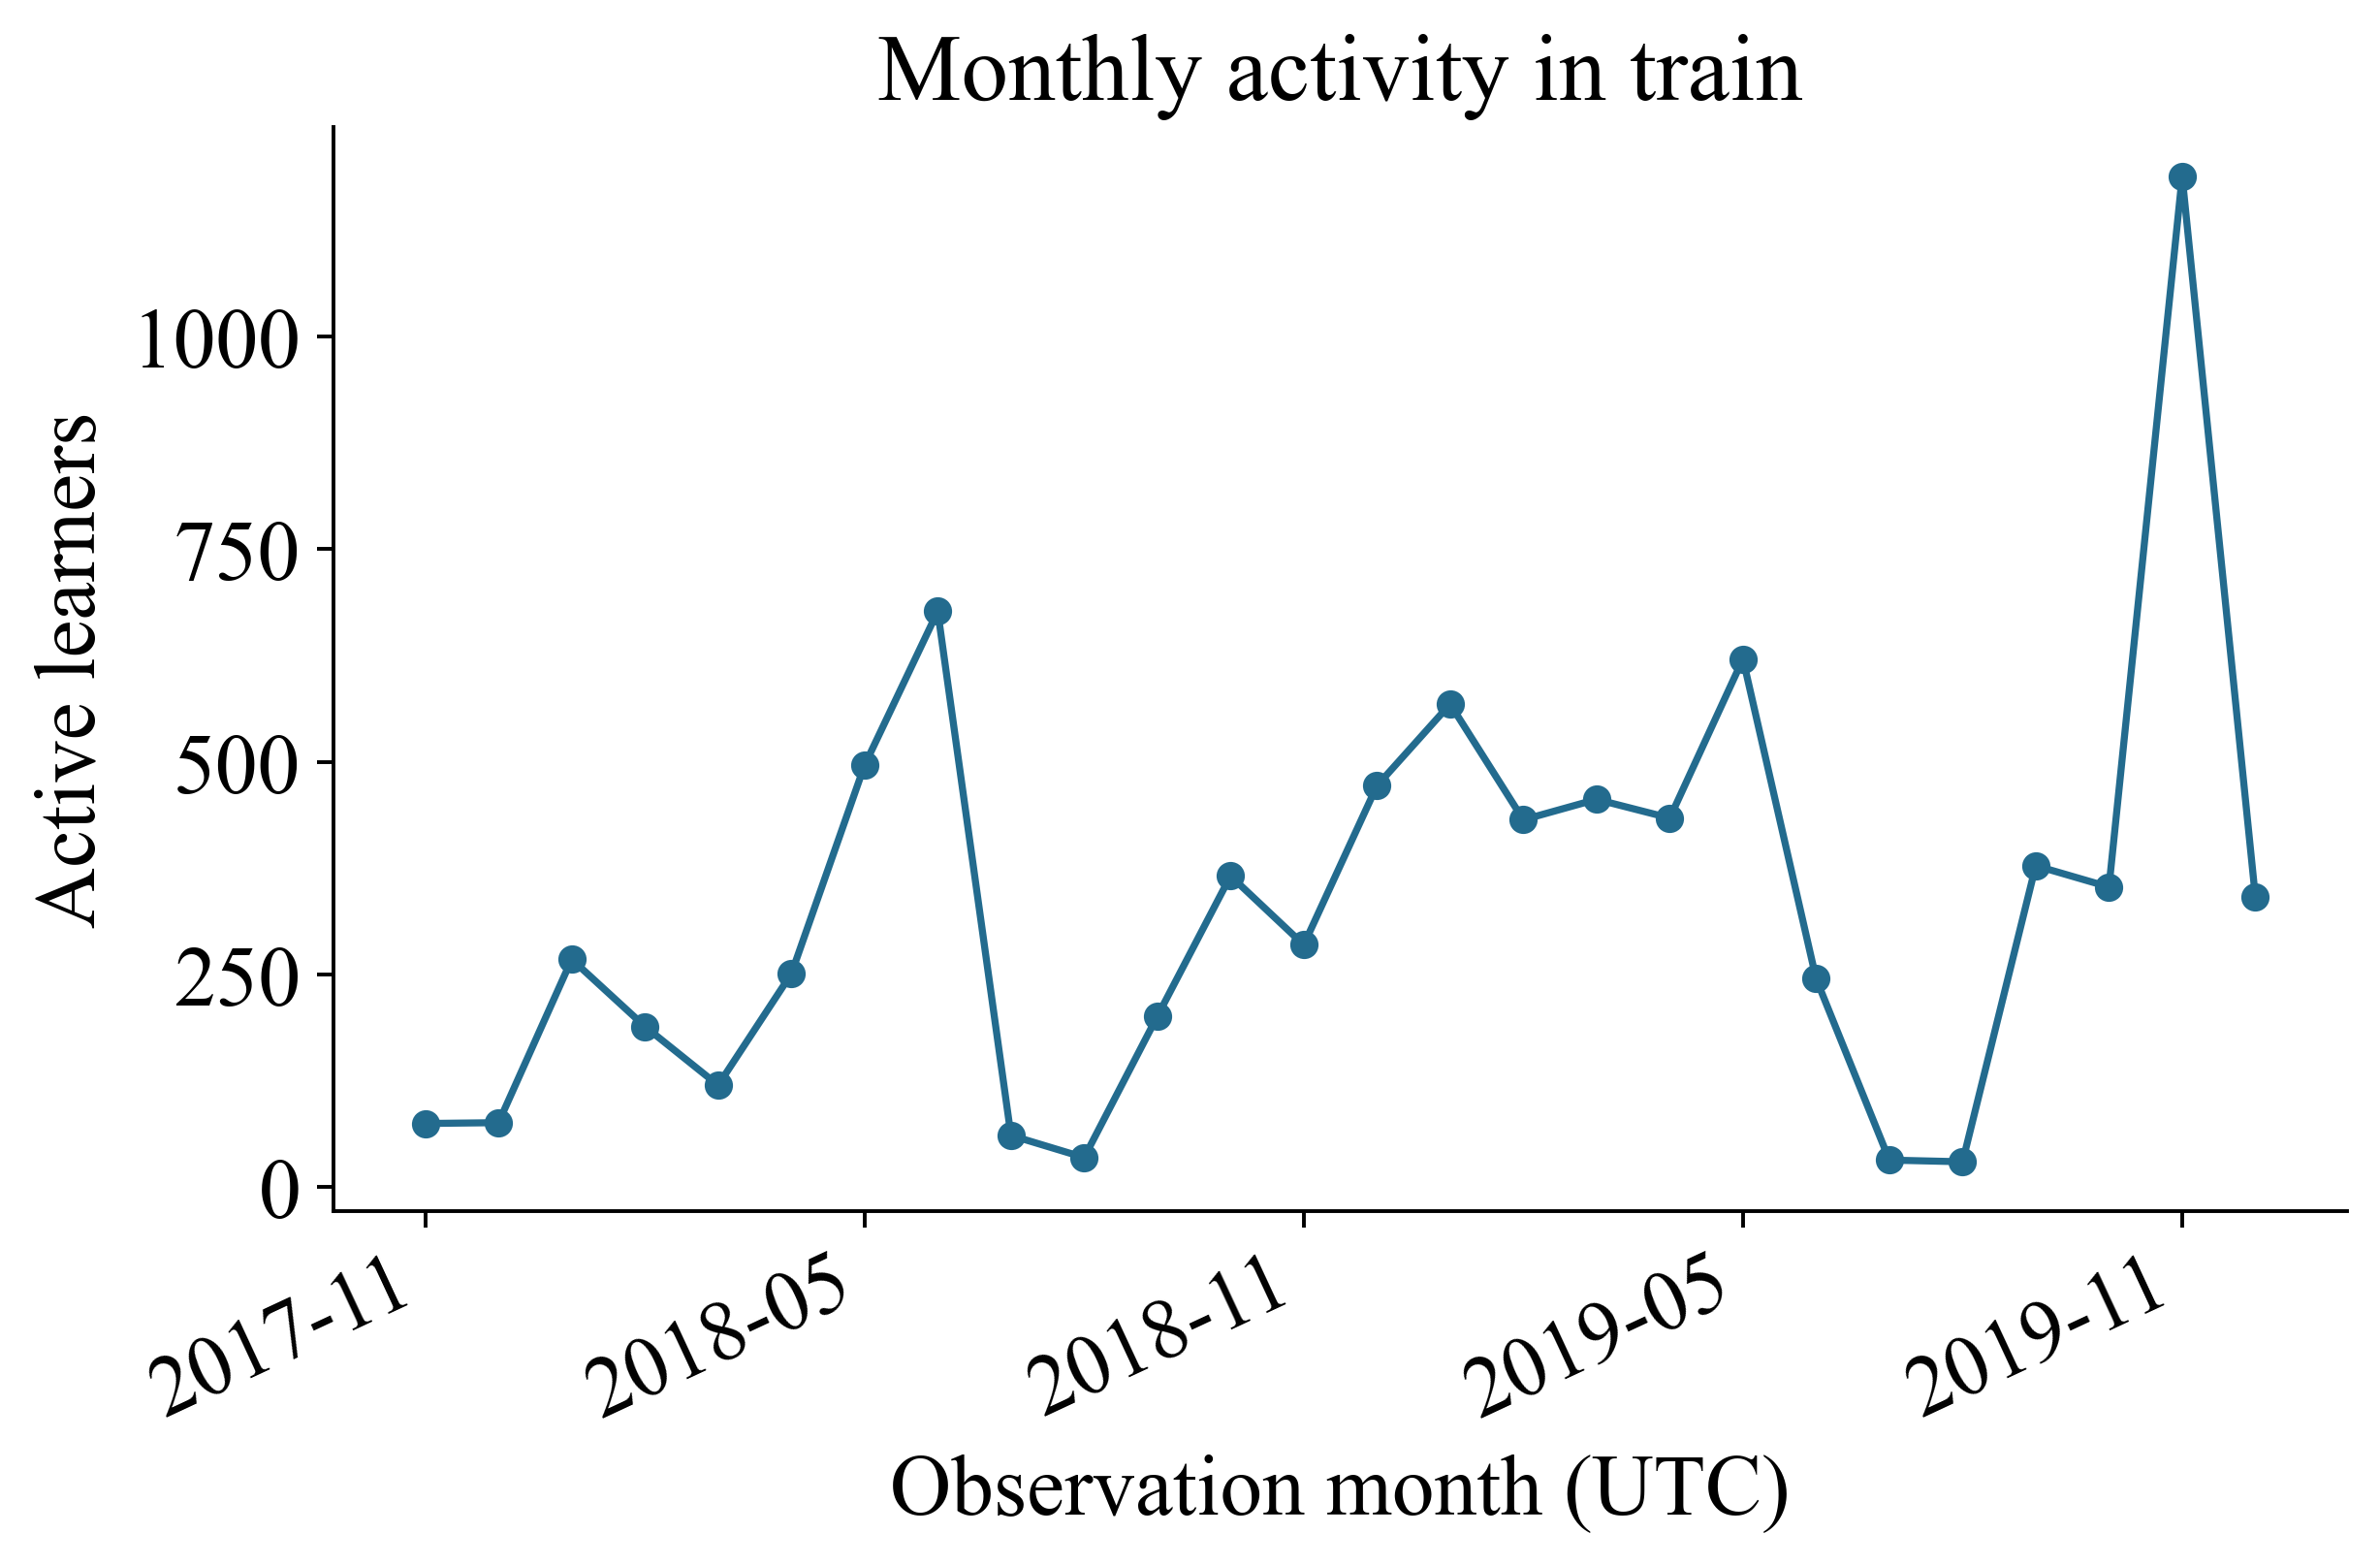

In [12]:
train_events = events[events.student.isin(train_students)]
monthly = (
    train_events.assign(month=train_events.timestamp.dt.strftime("%Y-%m"))
    .groupby("month")
    .agg(active_students=("student", "nunique"), events=("id", "size"))
    .reset_index()
)
monthly.to_csv(ROOT / "Tables/01_monthly_activity.csv", index=False)
fig, ax = plt.subplots(figsize=(6.9, 4.5), layout="constrained")
x = np.arange(len(monthly))
ax.plot(x, monthly.active_students, color="#236B8E", marker="o", markersize=5)
step = max(1, int(np.ceil(len(monthly) / 5)))
ax.set_xticks(x[::step], monthly.month.iloc[::step], rotation=25, ha="right")
ax.set(
    xlabel="Observation month (UTC)",
    ylabel="Active learners",
    title="Monthly activity in train",
)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "01_monthly_activity")
plt.show()

**Interpretation.** Activity varies by month and reaches a pronounced peak at the end of 2019. The irregular collection is taken into account when discussing the generalisation of the results.

## Quality of raw measurements in the training part

Outliers in duration and in the number of actions are described but not removed automatically. A long duration may include a user break; without additional checking it cannot be called active learning time. Zero-length and empty programs are treated as genuine interface states unless they contradict the schema.

In [13]:
train_attempts = attempts[attempts.student.isin(train_students)].copy()
quality_rows = []
for col, label in [
    ("time", "Duration, s"),
    ("n_edits", "Edits"),
    ("n_executions", "Runs"),
]:
    values = train_attempts[col]
    q1, q3 = values.quantile([0.25, 0.75])
    high = q3 + 1.5 * (q3 - q1)
    quality_rows.append(
        [
            label,
            len(values),
            values.isna().sum(),
            values.median(),
            values.quantile(0.95),
            values.max(),
            (values > high).mean(),
        ]
    )
table(
    pd.DataFrame(
        quality_rows,
        columns=[
            "Measure",
            "n",
            "Missing",
            "Median",
            "P95",
            "Maximum",
            "Share above the IQR bound",
        ],
    ),
    "Table 10. Duration and number of actions in train",
    "01_measurement_quality",
)

Table 10. Duration and number of actions in train

,Measure,n,Missing,Median,P95,Maximum,Share above the IQR bound
0,"Duration, s",115649,0,56.0,546.0,652762,0.109
1,Edits,115649,0,7.0,40.0,833,0.081
2,Runs,115649,0,2.0,12.0,278,0.087


**Interpretation.** The median duration is 56 s, whereas the maximum exceeds seven days. Long intervals may include pauses; they cannot automatically be regarded as skill acquisition time.

## Availability of raw school features

How often will a future school prediction operate without teacher information? Missingness is assessed on train. Missingness indicators are included in the pipeline; medians are computed only within training folds. The pre-test score and the final target are not imputed when forming the main longitudinal sample.

In [14]:
school_train = eligible[eligible.split.eq("train")]
missing_teacher = school_train[teacher_cols].isna()
school_missing = pd.DataFrame(
    [
        [
            "Pre-test score",
            len(school_train),
            school_train[pre].isna().mean(),
        ],
        [
            "School grade",
            len(school_train),
            school_train["Students' grade"].isna().mean(),
        ],
        [
            "All 16 teacher items missing",
            len(school_train),
            missing_teacher.all(axis=1).mean(),
        ],
        [
            "At least one teacher item missing",
            len(school_train),
            missing_teacher.any(axis=1).mean(),
        ],
    ],
    columns=["Measure", "n", "Missing share"],
)
table(
    school_missing,
    "Table 11. Availability of raw school information",
    "01_school_missingness",
)

Table 11. Availability of raw school information

,Measure,n,Missing share
0,Pre-test score,909,0.000
1,School grade,909,0.000
2,All 16 teacher items missing,909,0.149
3,At least one teacher item missing,909,0.149


**Interpretation.** The pre-test score and the school grade are available in all 909 train rows. Teacher information is jointly missing in approximately 14.9% of rows; the model must support this regime.

## Length of the observed learning trajectory

What share of learners has a long history? The curve shows the share of learners with at least a given number of distinct visited tasks. The unit of analysis is the train learner, not the event; this does not repeat the sample-size table.

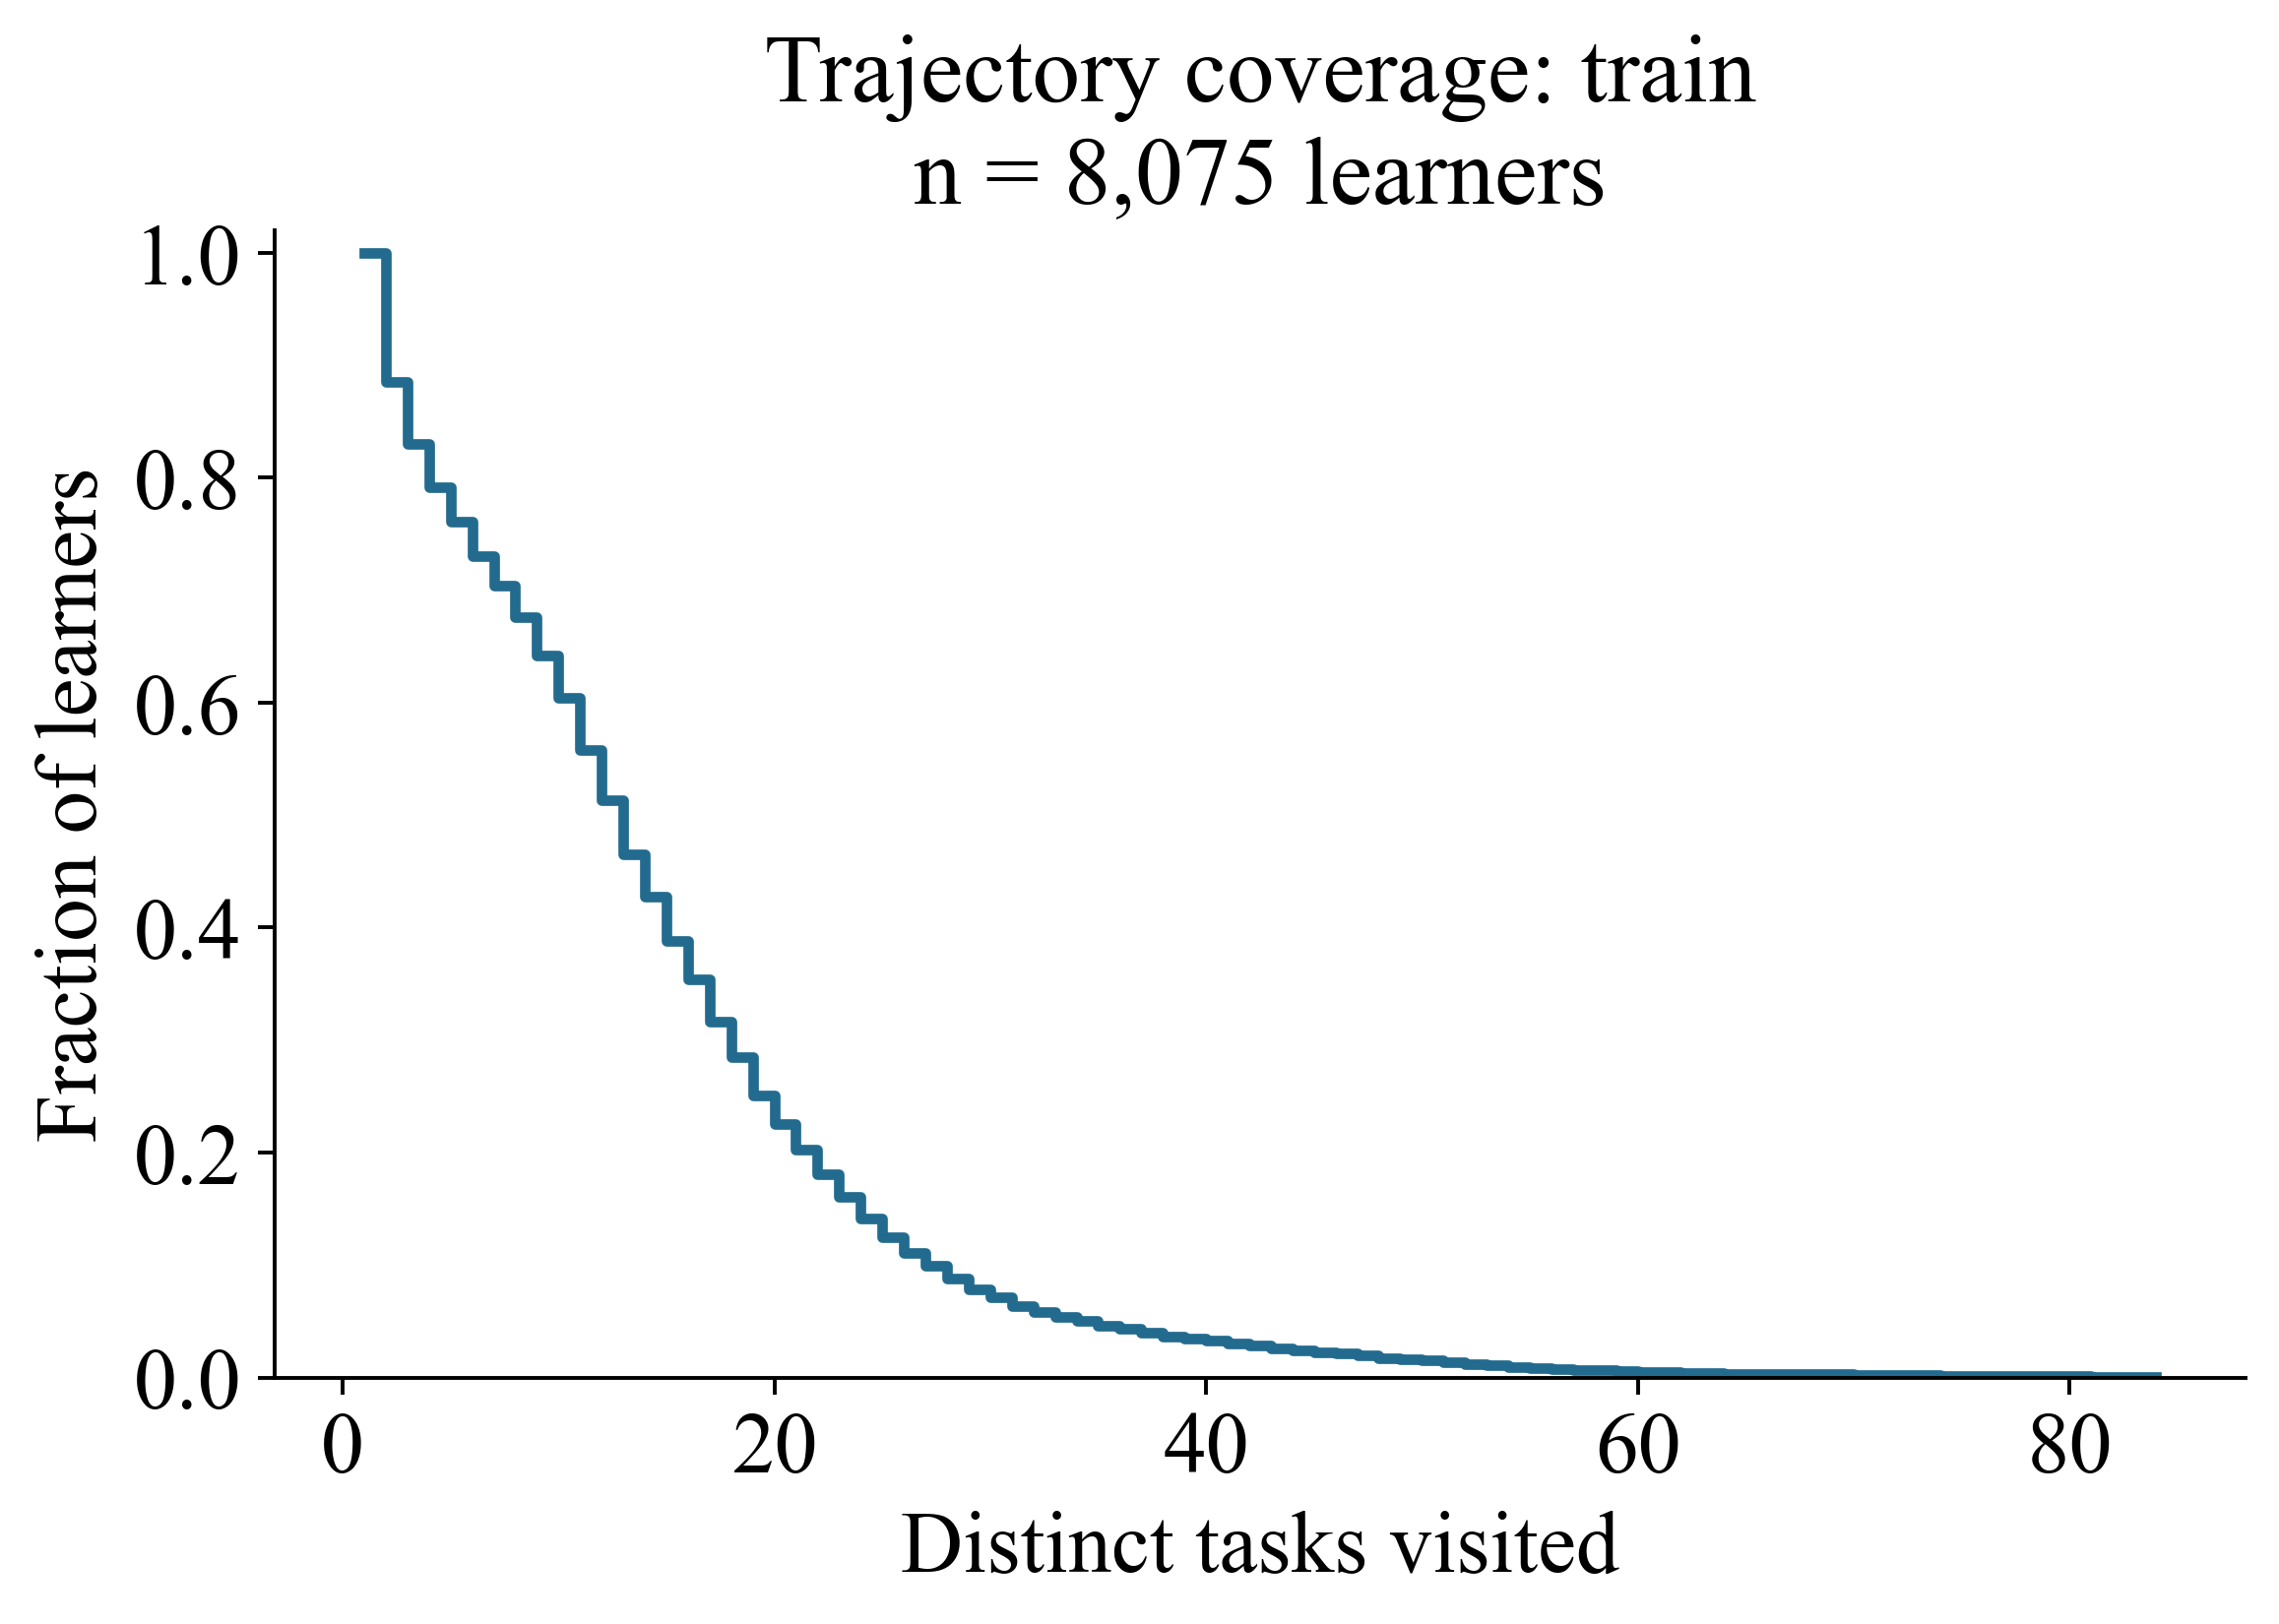

In [15]:
learner_task_counts = train_cohort.groupby("student").problem.nunique()
thresholds = np.arange(1, int(learner_task_counts.max()) + 1)
retained = np.array(
    [(learner_task_counts >= count).mean() for count in thresholds]
)
pd.DataFrame(
    {"minimum_tasks": thresholds, "fraction_learners": retained}
).to_csv(ROOT / "Tables/01_trajectory_length.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
ax.step(thresholds, retained, where="post", color="#236B8E", linewidth=2.2)
ax.set(
    xlabel="Distinct tasks visited",
    ylabel="Fraction of learners",
    ylim=(0, 1.02),
    title=f"Trajectory coverage: train\nn = {len(learner_task_counts):,} learners",
)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "01_trajectory_length")
plt.show()

**Interpretation.** The share of learners decreases rapidly as the number of visited tasks increases. A long context is available for only a small part of the sample; the short-history regime must be evaluated separately.

## Concentration of observations across tasks

Does the archive cover the tasks uniformly? The cumulative curve ranks tasks by the number of first visits. The diagonal denotes uniform coverage; the deviation characterises concentration, not model quality.

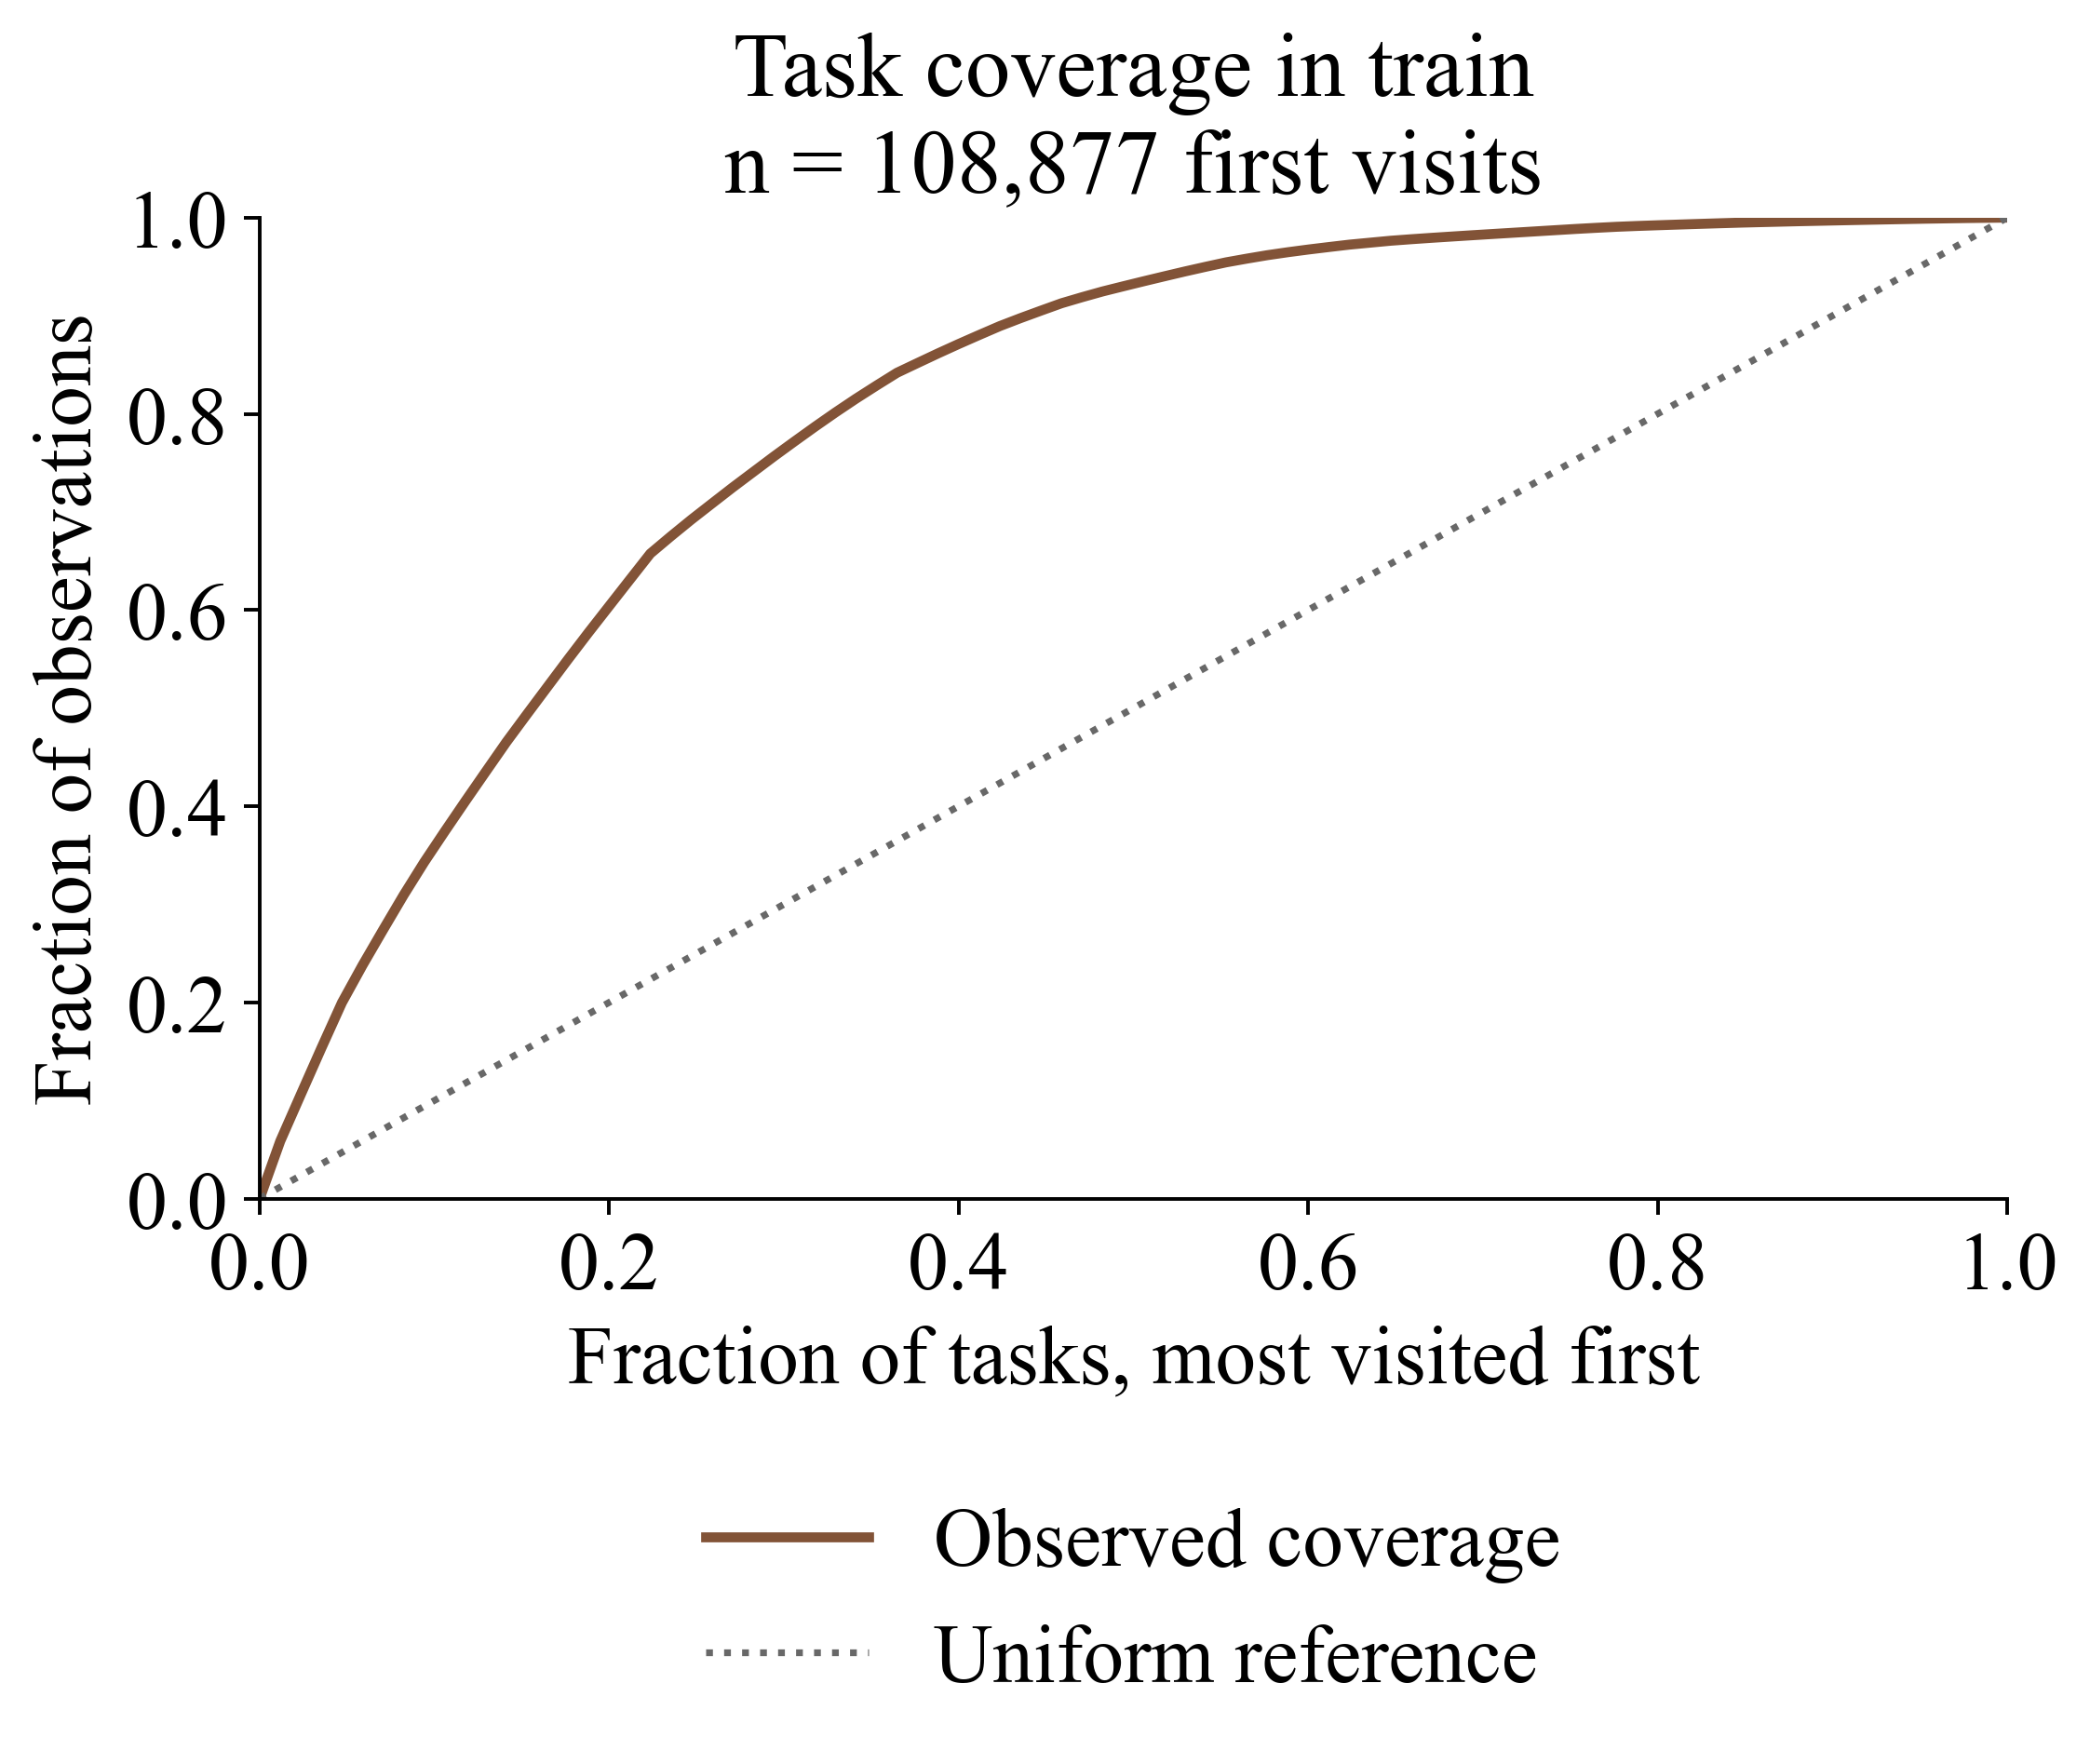

In [16]:
task_exposure = (
    train_cohort.groupby("problem").size().sort_values(ascending=False)
)
exposure_fraction = task_exposure.cumsum().to_numpy() / task_exposure.sum()
task_fraction = np.arange(1, len(task_exposure) + 1) / len(task_exposure)
pd.DataFrame(
    {
        "problem": task_exposure.index,
        "n": task_exposure.to_numpy(),
        "task_fraction": task_fraction,
        "observation_fraction": exposure_fraction,
    }
).to_csv(ROOT / "Tables/01_task_concentration.csv", index=False)
fig, ax = plt.subplots(figsize=(6.3, 5.3), layout="constrained")
ax.plot(
    np.r_[0, task_fraction],
    np.r_[0, exposure_fraction],
    color="#825337",
    linewidth=2.2,
    label="Observed coverage",
)
ax.plot(
    [0, 1], [0, 1], color="#686868", linestyle=":", label="Uniform reference"
)
ax.set(
    xlabel="Fraction of tasks, most visited first",
    ylabel="Fraction of observations",
    title=f"Task coverage in train\nn = {len(train_cohort):,} first visits",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.24), frameon=False, ncol=1
)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "01_task_concentration")
plt.show()

**Interpretation.** The curve lies substantially above the uniform diagonal: a small share of tasks accounts for a large share of visits. An average metric therefore reflects frequently visited tasks more strongly; separate results by task and by section are useful.

## Duration and editing: joint structure

Are long episodes accompanied by a larger number of program changes? Logarithmic axes retain all observations and reveal the density without removing the tails. Duration is not interpreted as continuous working time.

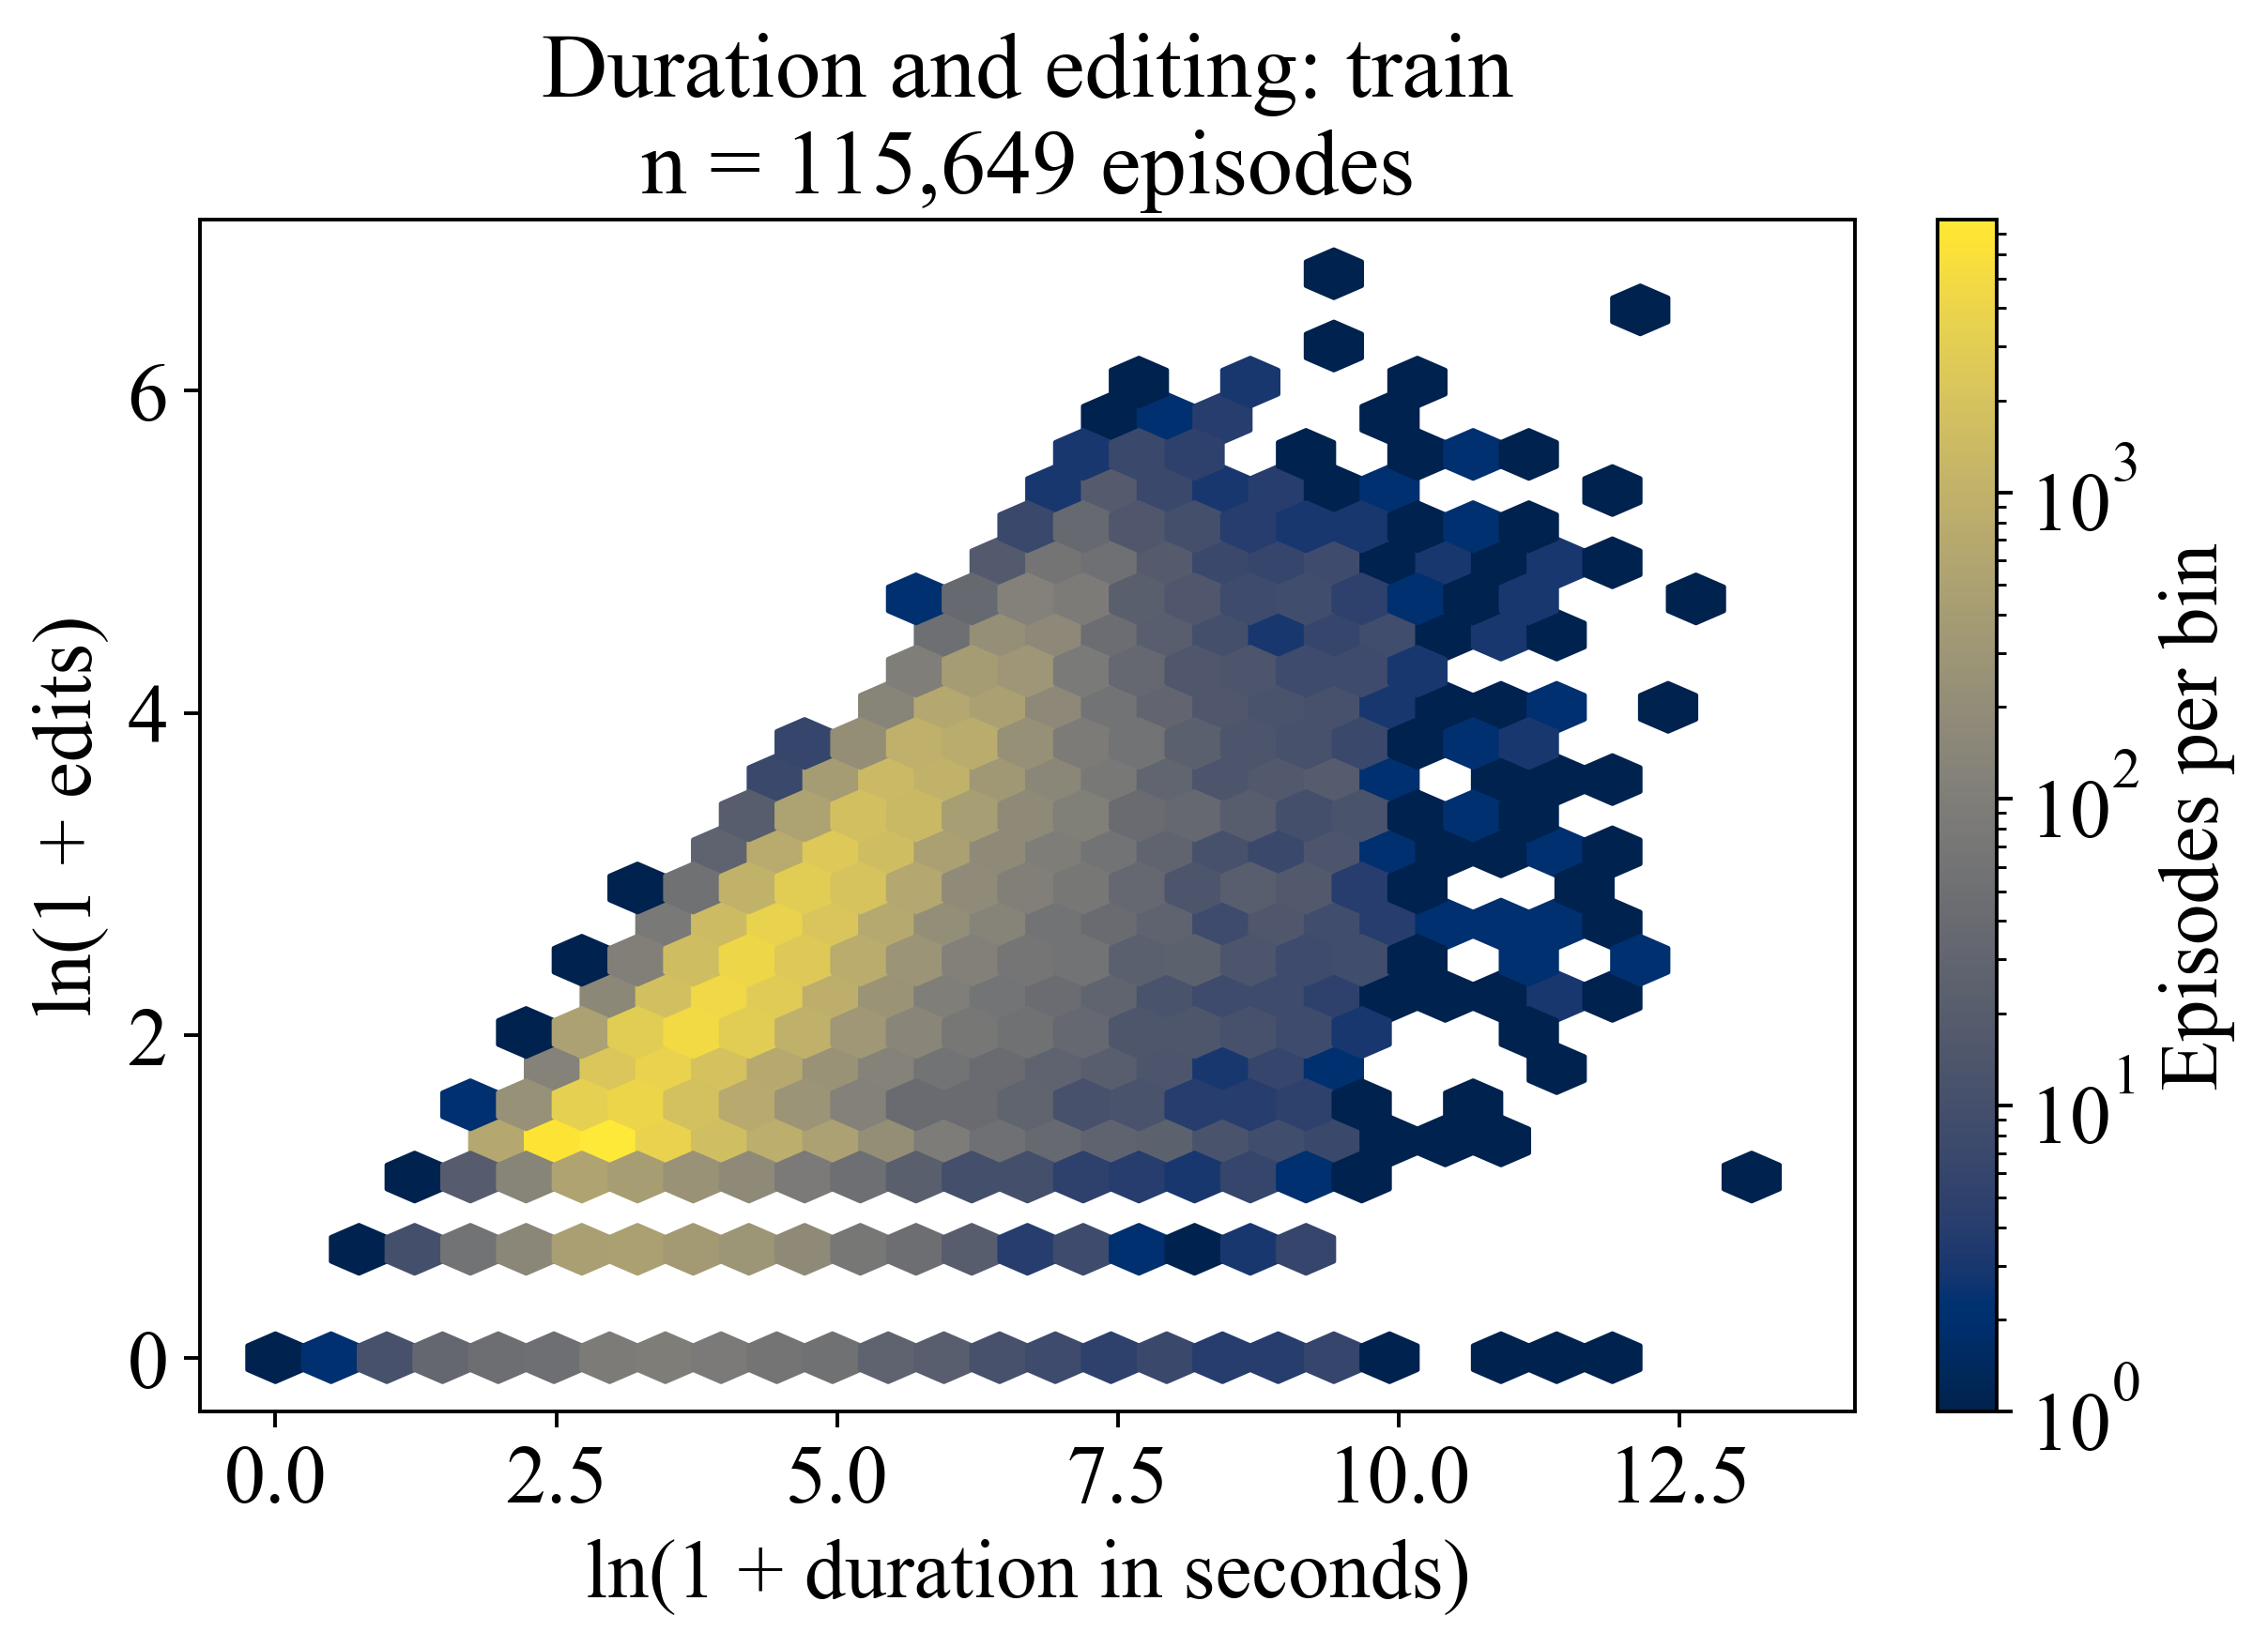

In [17]:
from matplotlib.colors import LogNorm

joint_duration = train_attempts[["time", "n_edits"]].copy()
assert joint_duration.ge(0).all().all()
joint_duration.to_csv(ROOT / "Tables/01_duration_edit_source.csv", index=False)
fig, ax = plt.subplots(figsize=(6.8, 4.9), layout="constrained")
artist = ax.hexbin(
    np.log1p(joint_duration.time),
    np.log1p(joint_duration.n_edits),
    gridsize=27,
    mincnt=1,
    norm=LogNorm(),
    cmap="cividis",
)
ax.set(
    xlabel="ln(1 + duration in seconds)",
    ylabel="ln(1 + edits)",
    title=f"Duration and editing: train\nn = {len(joint_duration):,} episodes",
)
fig.colorbar(artist, ax=ax, label="Episodes per bin")
save_figure(fig, "01_duration_edit_density")
plt.show()

**Interpretation.** The bulk of the density increases jointly in duration and in the number of edits, but very long episodes with few actions also occur. Duration contains information about pauses and does not replace a direct measure of learning effort.

## Agreement between initial and final school results

How are the two cCTt measurements related in the independent school branch? The density of pairs is constructed on train only. The diagonal denotes equal scores. A position above the diagonal does not by itself prove an effect of the educational intervention: there is no control comparison here.

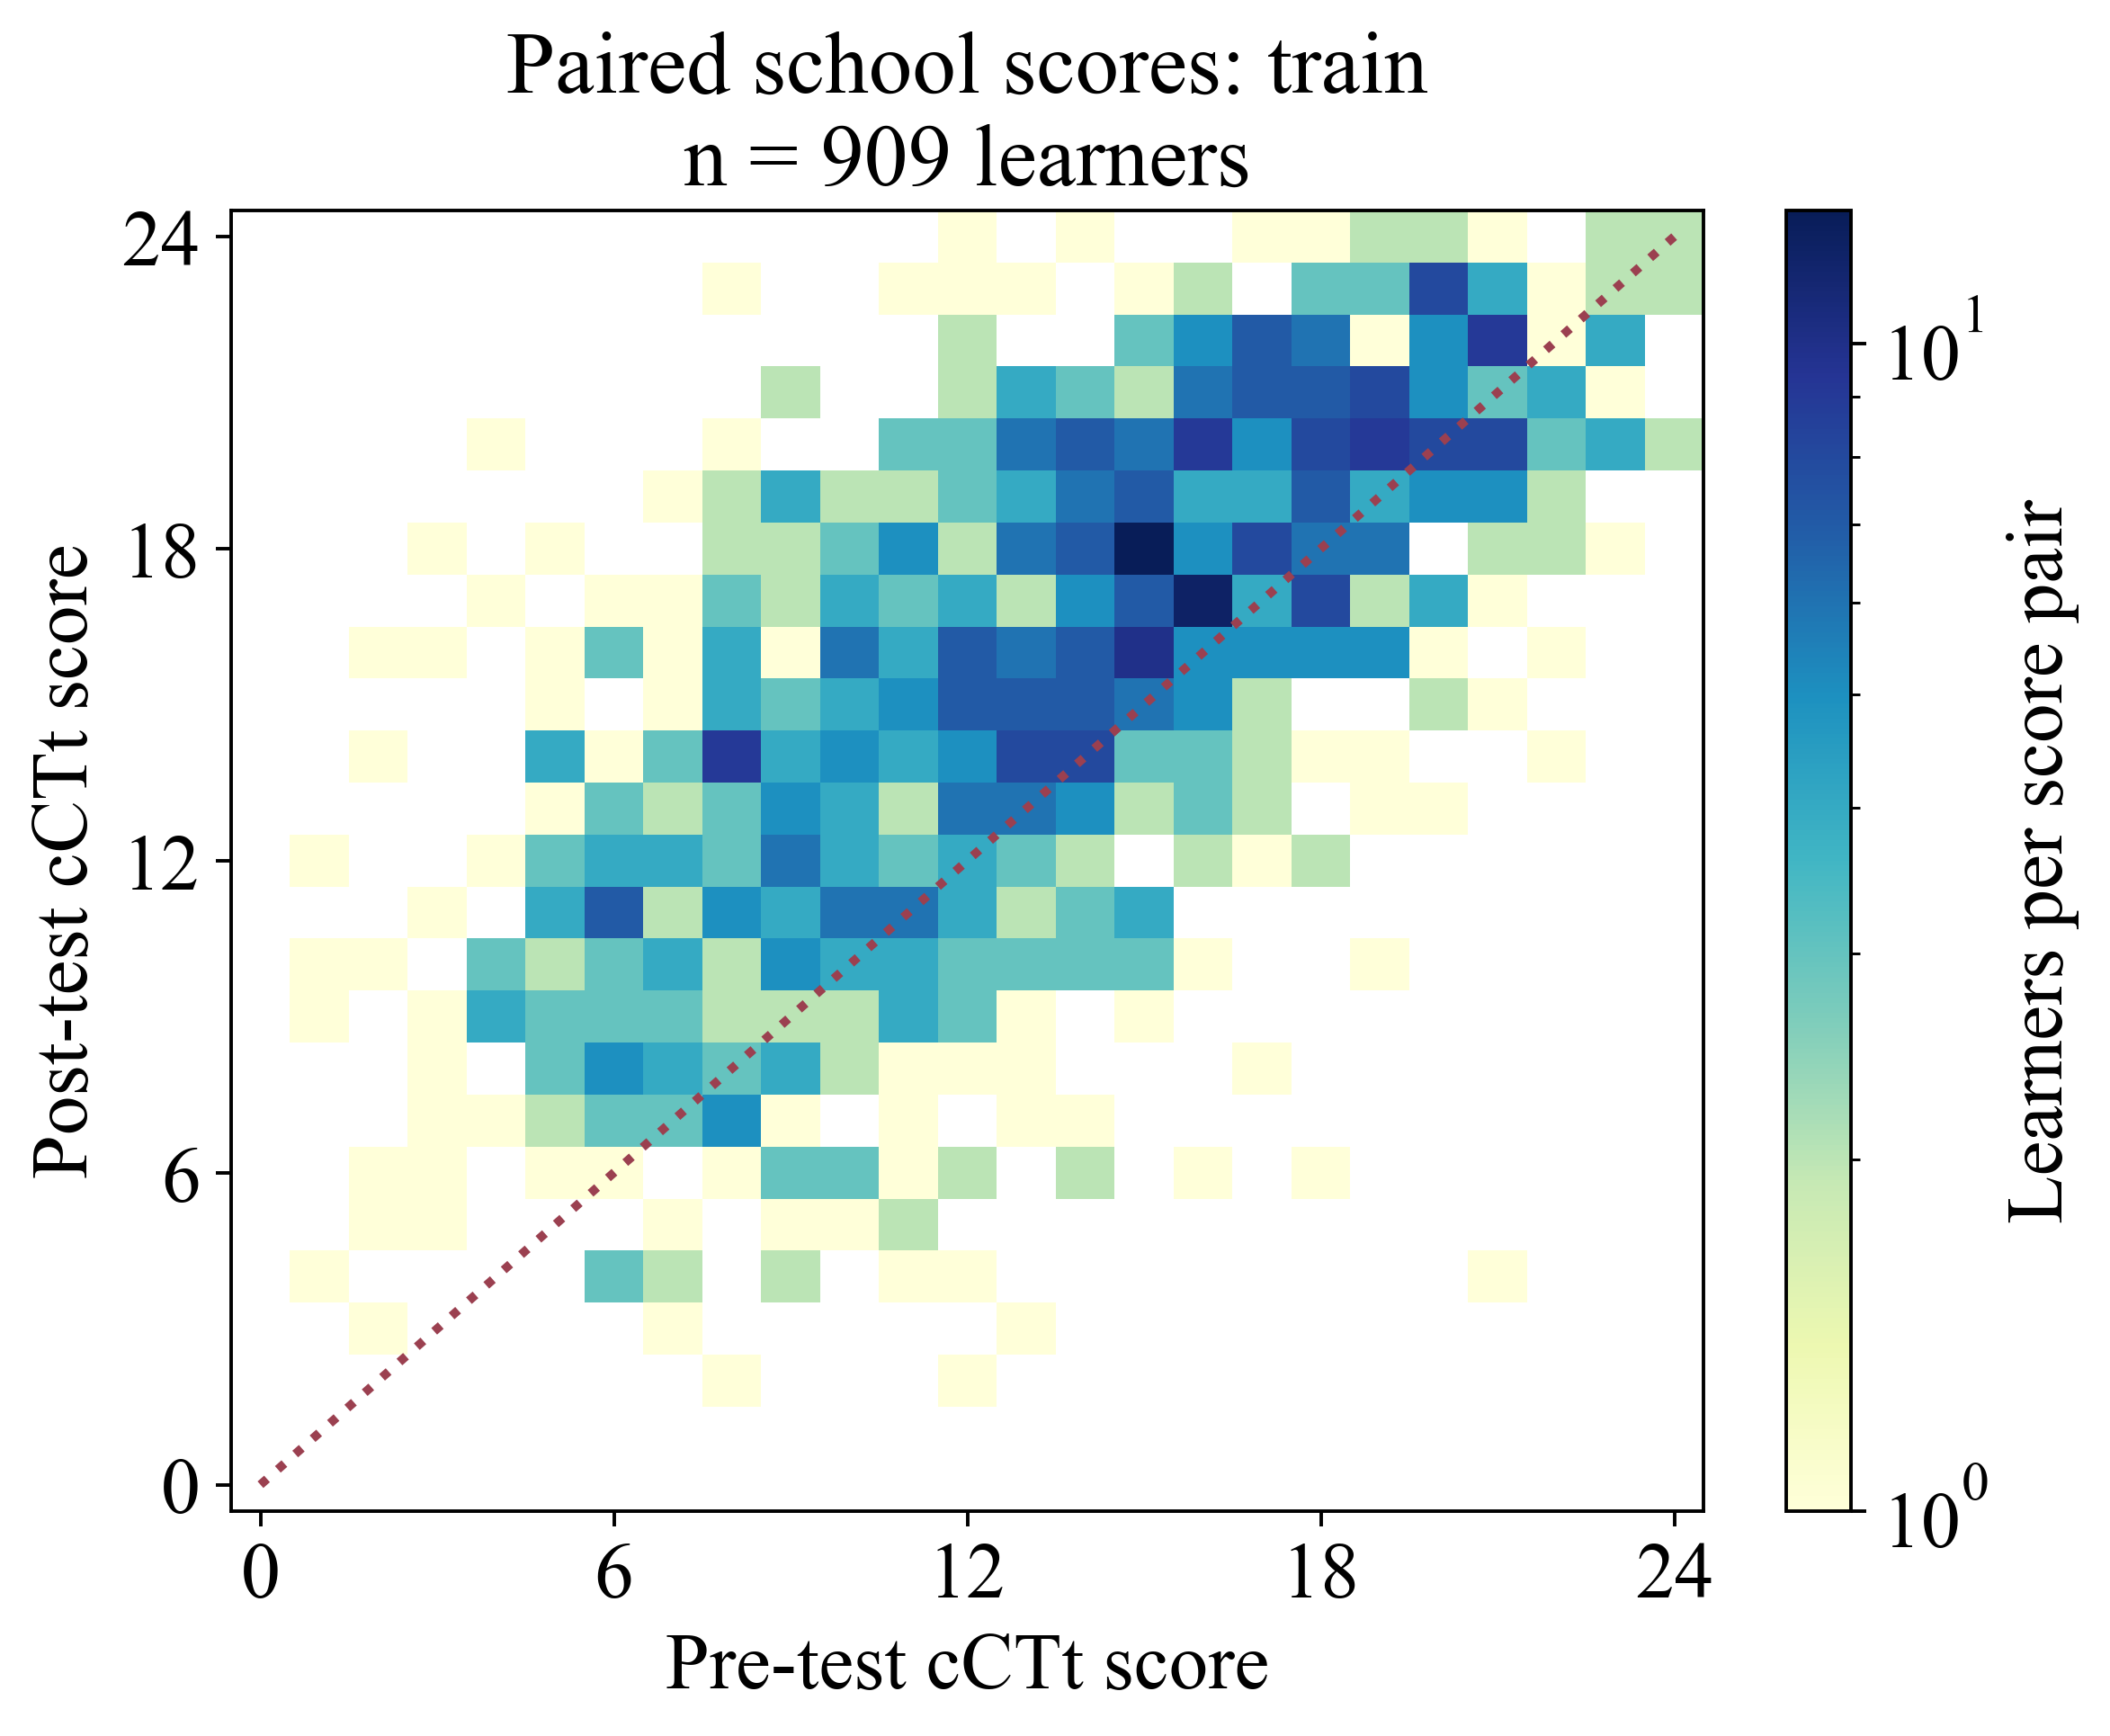

In [18]:
school_pairs = school_train[[pre, post]].copy()
school_pairs.to_csv(ROOT / "Tables/01_school_paired_scores.csv", index=False)
fig, ax = plt.subplots(figsize=(6.6, 5.4), layout="constrained")
artist = ax.hist2d(
    school_pairs[pre],
    school_pairs[post],
    bins=[np.arange(-0.5, 25, 0.999999), np.arange(-0.5, 25, 0.999999)],
    norm=LogNorm(),
    cmap="YlGnBu",
    cmin=1,
)[3]
ax.plot([0, 24], [0, 24], color="#9B4050", linestyle=":", linewidth=2)
ax.set(
    xlabel="Pre-test cCTt score",
    ylabel="Post-test cCTt score",
    xlim=(-0.5, 24.5),
    ylim=(-0.5, 24.5),
    xticks=[0, 6, 12, 18, 24],
    yticks=[0, 6, 12, 18, 24],
    title=f"Paired school scores: train\nn = {len(school_pairs):,} learners",
)
fig.colorbar(artist, ax=ax, label="Learners per score pair")
save_figure(fig, "01_school_score_density")
plt.show()

**Interpretation.** The initial and final scores show a positive relationship. The density of pairs is visible on both sides of the diagonal; the pre-test score is a necessary baseline for the subsequent regression comparison.

## Temporal boundary of available information

What may be used at prediction time? The diagram records the research design, not a measured effect: only events observed strictly before the start of the new task are used. A past attempt may continue after the prediction time; only its already observed prefix is available. Events of the current task and future continuations are excluded from the inputs.

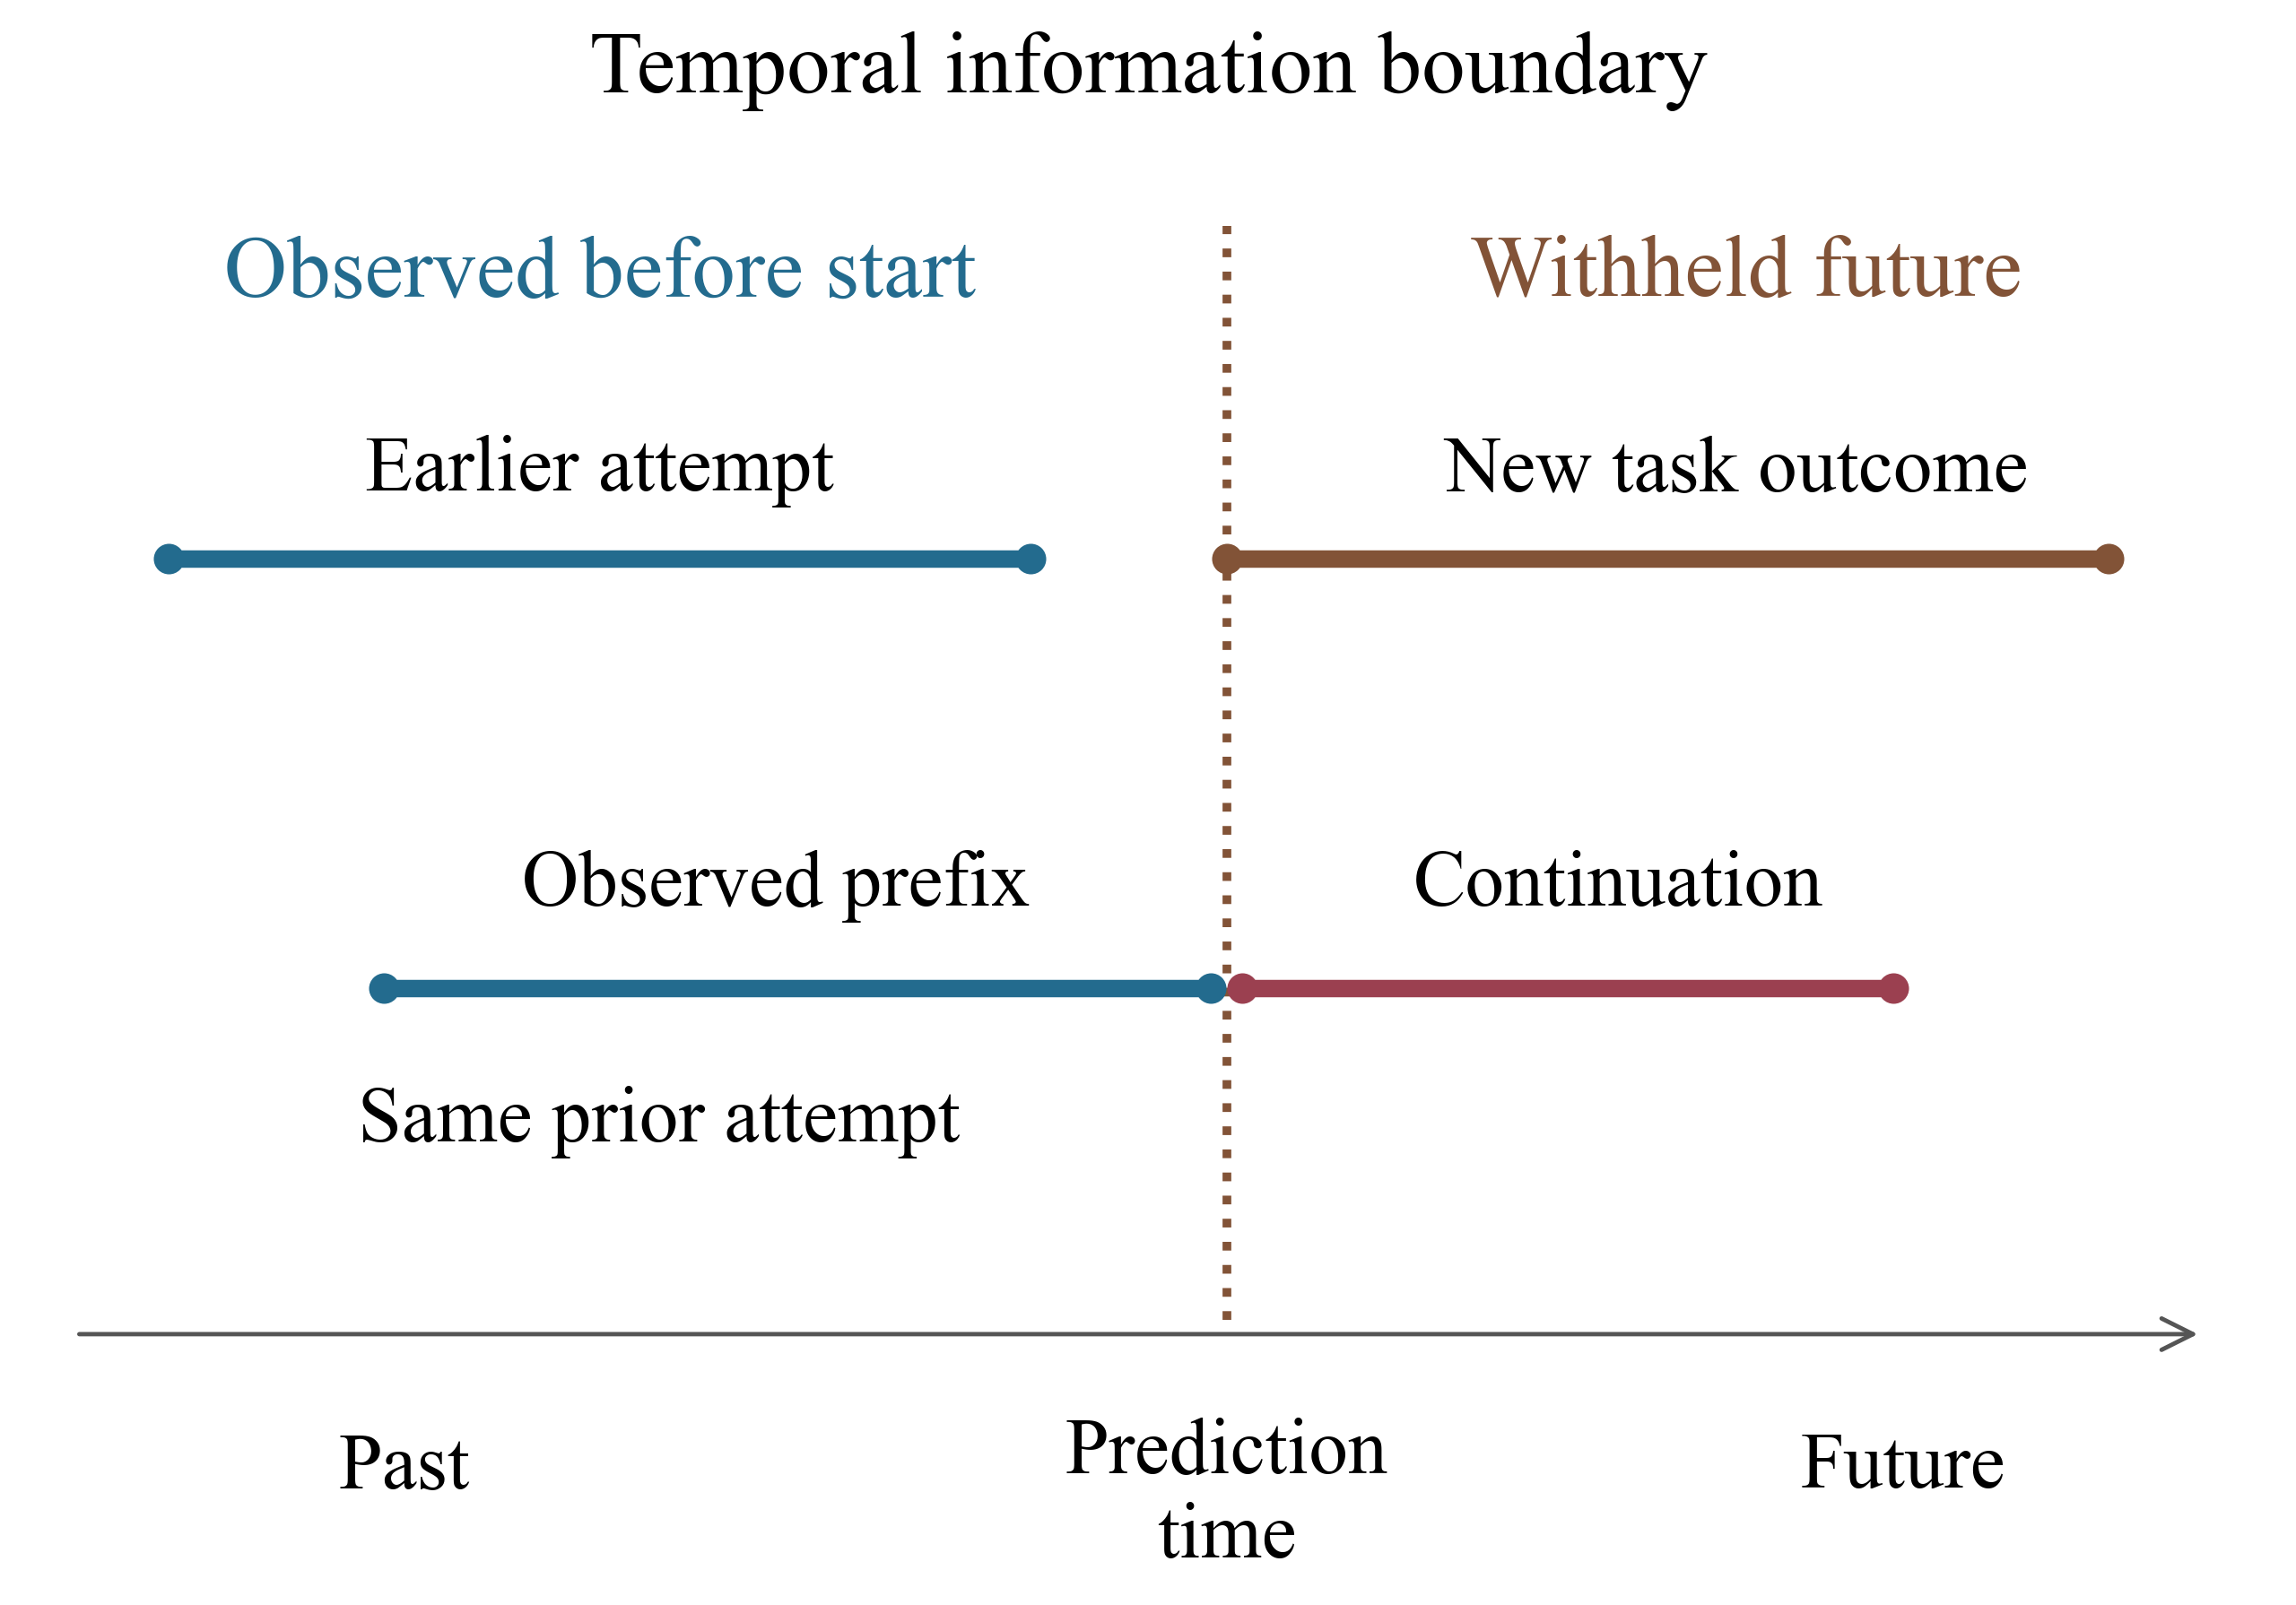

In [19]:
fig, ax = plt.subplots(figsize=(7.2, 5.0), layout="constrained")
ax.set_xlim(-6.1, 5.3)
ax.set_ylim(-1.2, 3.9)
ax.axis("off")
ax.plot([0, 0], [-0.3, 3.65], color="#825337", linestyle=":", linewidth=2)
ax.annotate(
    "",
    xy=(5.0, -0.35),
    xytext=(-5.9, -0.35),
    arrowprops={"arrowstyle": "->", "color": "#555555"},
)
ax.text(
    -3.2,
    3.4,
    "Observed before start",
    ha="center",
    fontsize=20,
    color="#236B8E",
)
ax.text(
    2.65, 3.4, "Withheld future", ha="center", fontsize=20, color="#825337"
)
ax.plot([-5.4, -1.0], [2.45, 2.45], color="#236B8E", linewidth=4, marker="o")
ax.text(-3.2, 2.7, "Earlier attempt", ha="center", fontsize=18)
ax.plot([0, 4.5], [2.45, 2.45], color="#825337", linewidth=4, marker="o")
ax.text(2.6, 2.7, "New task outcome", ha="center", fontsize=18)
ax.plot([-4.3, -0.08], [0.9, 0.9], color="#236B8E", linewidth=4, marker="o")
ax.plot([0.08, 3.4], [0.9, 0.9], color="#9B4050", linewidth=4, marker="o")
ax.text(-2.3, 1.2, "Observed prefix", ha="center", fontsize=18)
ax.text(2.0, 1.2, "Continuation", ha="center", fontsize=18)
ax.text(-2.9, 0.35, "Same prior attempt", ha="center", fontsize=18)
ax.text(0, -0.65, "Prediction\ntime", ha="center", va="top", fontsize=18)
ax.text(-4.2, -0.9, "Past", ha="center", fontsize=18)
ax.text(3.45, -0.9, "Future", ha="center", fontsize=18)
ax.set_title("Temporal information boundary", fontsize=20, pad=15)
save_figure(fig, "01_prediction_boundary")
plt.show()

**Interpretation.** For an ongoing past attempt, the model receives only its observed prefix. Context selection does not depend on when this attempt subsequently ends. This rules out the use of future completion as a hidden source of information.

## Scope of conclusions

The main branch contains 108,877 training, 23,326 validation and 22,899 locked test first visits. All 85 tasks are represented in every part: transfer to other learners is tested, not transfer to unseen tasks or to a future period. The archive makes it possible to study first-run prediction and the value of the action history; the pedagogical effect of adaptation requires a separate study.

The school files define a standalone task: there are no shared learners and no individual competence labels. The total cCTt score does not justify joint transfer across concepts. The next notebook constructs temporally available features, examines dependencies and fits transformations exclusively on train.